# Do one-year matrices describe a cohort? Markov tests, momentum and the ECB stability tests

**Question:** Does one one-year matrix describe how S&P ratings move, and which test detects which departure from the Markov model: a matrix that changes from year to year, or rating momentum?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 02 and 03 of this topic (the pooled matrix and the generators)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- test whether a one-year matrix is the same every year (time homogeneity) and whether each year agrees with the pooled matrix, and read a statistic that is eleven times its degrees of freedom;
- compute the ECB's matrix weighted bandwidth and migration z-tests on each cohort, and the mobility indices beside the speculative-grade default rate;
- run the order test and the momentum test on rating paths, and see on a dataset with planted momentum that the homogeneity test does not detect it;
- read the 200-dataset power study: how often each test rejects as the momentum or the stress grows;
- compare the five-year default frequency a cohort lived with what the one-year matrices project, and say which three different things the numbers count.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import estimators, mobility
from riskvalidation.transitions.em import em_generator
from riskvalidation.validation import rating_system, transitions as tests
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Five committed files of case C04, from ESMA's CEREP publication (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: the S&P annual and semester count tables, the pooled matrix, and what the case computed from them: `outputs.homogeneity`, `outputs.ecb`, `outputs.mobility`, `outputs.lifetime`.
- `data/derived/C04/models-transitions.json`: the generator fitted to S&P's counts, the known truth of the simulated datasets.
- `data/derived/C04/momentum.json` and `data/derived/C04/cycle.json`: two committed simulation studies of 200 seeded datasets per rung, one with a self-exciting downgrade intensity (momentum) of growing strength, one with the downgrade rates multiplied by a factor in the third year (a stressed regime).

CEREP has counts, never individual paths, so the real data can run the tests that need only count tables (homogeneity, the ECB tests) and cannot run the order test (it needs the state at three consecutive dates of each obligor) or the momentum test (it needs the path). Those two run on simulated paths, drawn here from the committed generator.

The next cell loads the files and builds the square count tables the tests take.

In [2]:
# Load the artifacts (the notebook sits three folders below the repository root) and square the count tables
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, models = load("sp.json"), load("models-transitions.json")
power_m, power_c = load("momentum.json"), load("cycle.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
cohorts = out["cohorts"]
annual = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in cohorts]
semesters = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["semesters"]]

print("annual tables:", len(annual), "| semester tables:", len(semesters))

annual tables: 26 | semester tables: 32


## Method

### Step 1: is the matrix the same every year?

Anderson and Goodman (1957) test time homogeneity: whether the transition probabilities $p_{ij}(t)$ are the same in every period against the pooled $\hat p_{ij}$. Their chi-square form (equation 3.8) sums, over the starting states $i$ (the absorbing default row carries no information), the periods $t$ and the end states $j$,

$$\chi^2 = \sum_i \sum_{t, j} n_i(t-1)\,\frac{\bigl(\hat p_{ij}(t) - \hat p_{ij}\bigr)^2}{\hat p_{ij}}$$

with $n_i(t-1)$ the ratings that started period $t$ in $i$. Under the null it is asymptotically chi-square with $(T-1)(m-1)$ degrees of freedom per row, where the empty cells and periods are removed (the engine's convention). The likelihood-ratio form (3.5) is in the result too. The engine's `rating_time_homogeneity` takes the stack of count tables.

The next cell calls it on the 26 annual tables and on the 32 semester tables and prints each statistic against its degrees of freedom: under the null the two are of the same size. A second table splits the annual statistic by starting grade.

In [3]:
# Time homogeneity across the 26 annual and the 32 semester tables, and the contribution of each grade
hom_annual = tests.rating_time_homogeneity(annual, model_id="STPGB", segment="annual")
hom_semesters = tests.rating_time_homogeneity(semesters, model_id="STPGB", segment="semesters")

for label, r in (("annual", hom_annual), ("semesters", hom_semesters)):
    dof = r.extras["dof"]
    print(f"{label:11s} chi2 = {r.statistic:10.2f} | dof = {dof} | chi2 / dof = {r.statistic / dof:.2f}",
          f"| p = {r.p_value:.3g}")
rows = hom_annual.extras["rows"]
print(f"{'grade':8s}{'chi2':>10s}{'dof':>8s}{'chi2 / dof':>12s}")
for row in rows:
    print(f"{grades[row['row']]:8s}{row['chi2']:10.2f}{row['dof']:8d}{row['chi2'] / row['dof']:12.2f}")

annual      chi2 =   12028.16 | dof = 1075 | chi2 / dof = 11.19 | p = 0
semesters   chi2 =   14248.61 | dof = 899 | chi2 / dof = 15.85 | p = 0
grade         chi2     dof  chi2 / dof
AAA         330.13     100        3.30
AA         5763.16     175       32.93
A          1562.54     175        8.93
BBB        1370.75     175        7.83
BB          971.37     175        5.55
B          1638.98     150       10.93
CCC-C       391.23     125        3.13


The next cell draws the chi-square of each starting grade over its degrees of freedom, with the value one that the null would give.

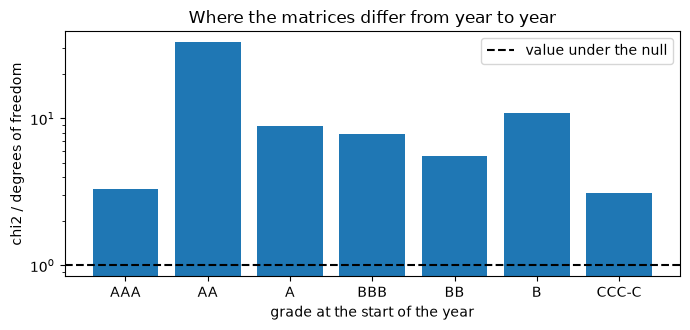

In [4]:
# Draw each grade's share of the homogeneity statistic per degree of freedom
ratio = [row["chi2"] / row["dof"] for row in rows]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar([grades[row["row"]] for row in rows], ratio, color="tab:blue")
ax.axhline(1.0, color="black", linestyle="--", label="value under the null")
ax.set_yscale("log")
ax.set_xlabel("grade at the start of the year")
ax.set_ylabel("chi2 / degrees of freedom")
ax.set_title("Where the matrices differ from year to year")
ax.legend()
fig.tight_layout()
plt.show()

The statistic is far above its degrees of freedom, and the p-value is below the smallest number double precision holds (the engine reports 0). With about 170,000 rating-years the test has the power to see any difference between years, and the matrix does change from year to year. The figure shows that every grade contributes more than the null allows, AA the most per degree of freedom (32.93) and CCC-C the least (3.13). What the test does not say is which departure from the Markov model produced the rejection, a change of regime over time, momentum or something else, which Step 5 returns to.

### Step 2: each year against the pooled matrix

A second reading asks, for each year separately, whether its counts are compatible with the pooled matrix as a specified reference. The engine's `rating_matrix_reference` uses by default the likelihood ratio $2\sum n_{ij} \log(\hat p_{ij} / p^0_{ij})$ (the likelihood-ratio analogue of Anderson and Goodman's equation 3.1, chosen because it held its size where the printed form did not) and also reports any move the pooled matrix calls impossible (a count where the reference has zero).

The next cell first pools the 26 tables into the reference matrix with the engine, then runs the test on each cohort and counts the rejections at 5% and 1%.

In [5]:
# Pool the tables into the reference matrix, then test each annual cohort against it
gone = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in cohorts]
P = estimators.pooled_cohort(annual, gone, treatment="exclude")["matrix"]
refs = [tests.rating_matrix_reference(t, P, model_id="STPGB", segment=c["label"]) for t, c in zip(annual, cohorts)]
stat = np.array([r.statistic for r in refs])
dof = np.array([r.extras["dof"] for r in refs])
pvals = np.array([r.p_value for r in refs])
years = [c["label"] for c in cohorts]

print("cohorts rejected at 5%:", int((pvals < 0.05).sum()), "of", len(refs), "| at 1%:", int((pvals < 0.01).sum()))
ratio = stat / dof
order = np.argsort(ratio)
print("LR / dof: smallest", round(float(ratio[order[0]]), 2), "in", years[order[0]])
print("LR / dof: largest three:", [(years[k], round(float(ratio[k]), 2)) for k in order[::-1][:3]])
print("cohorts with a move the pooled matrix calls impossible:",
      sum(1 for r in refs if r.extras["impossible_moves"]))

cohorts rejected at 5%: 26 of 26 | at 1%: 26
LR / dof: smallest 2.27 in 2012
LR / dof: largest three: [('2021', 55.27), ('2002', 16.83), ('2020', 13.44)]
cohorts with a move the pooled matrix calls impossible: 0


The next cell draws the statistic over its degrees of freedom for every year, the line at one being what a year drawn from the pooled matrix would give.

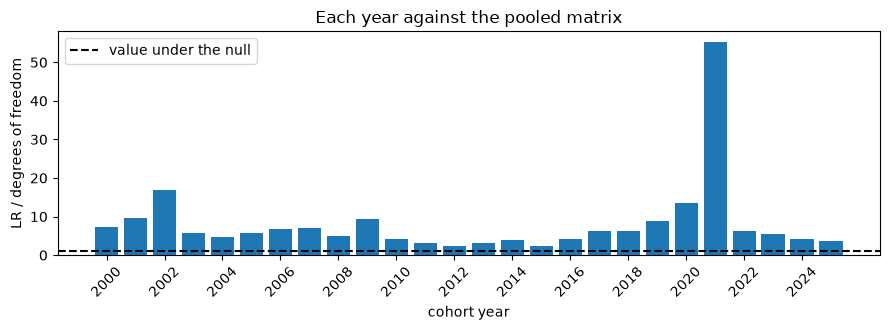

In [6]:
# Draw the likelihood-ratio statistic per degree of freedom of each year against the pooled matrix
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(years, stat / dof, color="tab:blue")
ax.axhline(1.0, color="black", linestyle="--", label="value under the null")
ax.set_xticks(range(0, len(years), 2))
ax.set_xticklabels(years[::2], rotation=45)
ax.set_xlabel("cohort year")
ax.set_ylabel("LR / degrees of freedom")
ax.set_title("Each year against the pooled matrix")
ax.legend()
fig.tight_layout()
plt.show()

Every one of the 26 years rejects the pooled matrix, the smallest statistic (2012, 2.27 per degree of freedom) as much as the largest (2021, 55.27). That is what a matrix pooled over regimes does to a single year, and none of the cohorts holds a move the pooled matrix calls impossible, so the rejections come from the size of the frequencies and not from empty cells. The figure shows that the departure is far from uniform: 2021 stands apart, 2002 and 2020 follow at 16.8 and 13.4, and the other years lie below 10. One bar per year cannot separate how much of that is the regime of the year and how much the number of ratings behind each cohort.

### Step 3: the ECB's stability tests on each cohort

The ECB's reporting template (ECB, 2019, section 2.5.5) asks two things of a rating system's migration matrix. The **matrix weighted bandwidth** (MWB, section 2.5.5.1) measures how far ratings migrate: for downgrades (upper) and upgrades (lower), the average distance of the migrations weighted by the obligors, relative to the largest possible distance from each grade; 0 when nobody migrates, 1 at the extreme. It is descriptive, so the default policy gives no light. The **migration z-tests** (section 2.5.5.2) check that, in each row, the frequency of moving does not increase when moving further from the diagonal: one z-test per off-diagonal cell against its neighbour closer to the diagonal. The engine adds a Holm adjustment across the cells and reports the smallest adjusted p-value. Both apply to the block of transitions between the performing grades.

The next cell runs both on the 7 x 7 performing block of every cohort and prints three cohorts: the first, the most mobile and the last.

In [7]:
# MWB and migration z-tests on the 7 x 7 performing block of every cohort
blocks = [np.array(c["counts"], dtype=float)[:, :7] for c in cohorts]
mwb = [rating_system.rating_mwb(b, model_id="STPGB", segment=c["label"]) for b, c in zip(blocks, cohorts)]
ztest = [rating_system.rating_migration_ztests(b, model_id="STPGB", segment=c["label"])
         for b, c in zip(blocks, cohorts)]
up = np.array([r.extras["mwb_upper"] for r in mwb])
down = np.array([r.extras["mwb_lower"] for r in mwb])
zp = np.array([r.p_value for r in ztest])

print("light of the MWB:", mwb[0].light.value, "| cohorts with a Holm p below 0.05:", int((zp < 0.05).sum()))
print(f"{'cohort':8s}{'MWB up':>12s}{'MWB down':>12s}{'p (Holm)':>12s}")
for k in (0, int(up.argmax()), len(up) - 1):
    print(f"{years[k]:8s}{up[k]:12.4f}{down[k]:12.4f}{zp[k]:12.4f}")

light of the MWB: not_evaluated | cohorts with a Holm p below 0.05: 2
cohort        MWB up    MWB down    p (Holm)
2000          0.2678      0.2878      0.9946
2001          0.2732      0.2699      0.0099
2025          0.2269      0.2310      1.0000


The next cell draws the two bandwidths by year, and beside them the smallest adjusted p-value of the z-tests with the 5% line.

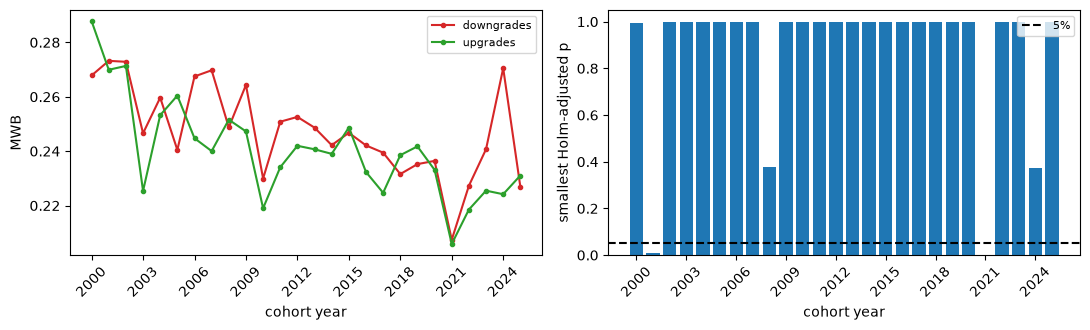

In [8]:
# Draw the matrix weighted bandwidth by year (left) and the smallest Holm-adjusted p of the z-tests (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.plot(years, up, color="tab:red", marker="o", markersize=3, label="downgrades")
left.plot(years, down, color="tab:green", marker="o", markersize=3, label="upgrades")
left.set_xticks(range(0, len(years), 3))
left.set_xticklabels(years[::3], rotation=45)
left.set_xlabel("cohort year")
left.set_ylabel("MWB")
left.legend(fontsize=8)
right.bar(years, zp, color="tab:blue")
right.axhline(0.05, color="black", linestyle="--", label="5%")
right.set_xticks(range(0, len(years), 3))
right.set_xticklabels(years[::3], rotation=45)
right.set_xlabel("cohort year")
right.set_ylabel("smallest Holm-adjusted p")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

The bandwidths describe how far ratings migrate, and they move between 0.2 and 0.3 with no trend that the ECB policy would turn into a light: the engine reports the MWB as not evaluated. The z-tests ask a sharper question, whether the frequency of moving ever grows when moving further from the diagonal, and after the Holm adjustment across cells only two of the 26 cohorts raise a flag, 2001 with a smallest p of 0.0099 and 2021 with a p close to zero. So the cohorts pass the ECB's stability tests that look at the shape of each matrix, while Step 1 showed that the matrices differ from one another. The two kinds of test answer different questions, and passing one does not clear the other.

### Step 4: how much does the matrix move, and when

The mobility indices summarise a whole matrix in one number. The engine's `svd_mobility` returns the mean singular value of $P - I$ (the index of Jafry and Schuermann, 2004) and `trace_mobility` the trace index $(n - \mathrm{tr} P)/(n-1)$. Both are 0 for an identity matrix.

The next cell computes both indices on the matrix of every cohort and on the pooled matrix, and sets them beside the speculative-grade default rate the artifact holds for each year.

In [9]:
# Mobility of every cohort's own matrix and of the pooled matrix, beside the speculative-grade default rate
own = [estimators.cohort(t, g, treatment="exclude")["matrix"] for t, g in zip(annual, gone)]
svd = np.array([mobility.svd_mobility(m) for m in own])
trace = np.array([mobility.trace_mobility(m) for m in own])
spec = np.array([np.nan if v is None else v for v in out["mobility"]["spec_default_rate"]], dtype=float)
ok = np.isfinite(spec)

print("pooled matrix: M_SVD =", round(mobility.svd_mobility(P), 4),
      "| trace index =", round(mobility.trace_mobility(P), 4))
print("most mobile year:", years[int(svd.argmax())], round(float(svd.max()), 4),
      "| least mobile:", years[int(svd.argmin())], round(float(svd.min()), 4))
print("correlation of M_SVD with the speculative-grade default rate:",
      round(float(np.corrcoef(svd[ok], spec[ok])[0, 1]), 3))

pooled matrix: M_SVD = 0.1353 | trace index = 0.1372
most mobile year: 2002 0.2189 | least mobile: 2023 0.0658
correlation of M_SVD with the speculative-grade default rate: 0.269


The next cell draws the two mobility indices on the left axis and the default rate on the right one.

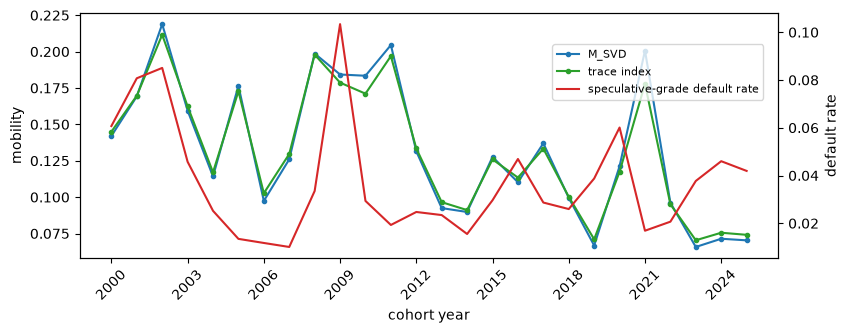

In [10]:
# Draw the mobility indices and the speculative-grade default rate by year
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(years, svd, color="tab:blue", marker="o", markersize=3, label="M_SVD")
ax.plot(years, trace, color="tab:green", marker="o", markersize=3, label="trace index")
ax.set_ylabel("mobility")
ax.set_xlabel("cohort year")
ax.set_xticks(range(0, len(years), 3))
ax.set_xticklabels(years[::3], rotation=45)
twin = ax.twinx()
twin.plot(years, spec, color="tab:red", label="speculative-grade default rate")
twin.set_ylabel("default rate")
fig.legend(loc="upper right", fontsize=8, bbox_to_anchor=(0.9, 0.88))
fig.tight_layout()
plt.show()

Mobility is high in the early 2000s, with its peak in 2002 (M_SVD 0.219), and low in recent years, with its minimum in 2023 (0.066). The default rate of the speculative grades follows the same cycle, peaking in 2001 to 2002 and 2009. Across the 26 years M_SVD correlates 0.27 with that default rate: movement and defaults are related but far from the same thing, because mobility counts upgrades as much as downgrades. The figure cannot say whether the quiet recent years are a calm cycle or a change in how the agency rates, which is what a stability test should keep apart.

### Step 5: order and momentum, on paths whose truth is known

Two more departures from the Markov model matter in practice. The **order** test (Anderson and Goodman, equation 3.12) asks whether the next state depends on the previous one as well as on the current one. The engine's default groups the previous and next states by direction (from a better grade, the same, a worse one; to a better, the same, a worse one), the grouping that momentum acts on. The **momentum** test (dos Reis, Pfeuffer and Smith, 2020) fits the hazard of leaving a grade as $\lambda(t) = q_i(t)\, e^{cZ}$ with $Z = 1$ for an obligor downgraded into its current grade, and tests $c = 0$ by a likelihood ratio.

Neither can run on CEREP's counts. The next cell draws two datasets from the committed generator, with a seed and the same number of obligors: one Markov, one where every downgrade raises the intensity of further downgrades (`RatingPaths` momentum with strength 0.125 and decay 1 per year, the strength at which the committed study recovers the hazard coefficient that dos Reis et al. estimate on Moody's data). It runs the three tests on each. The engine reports the fitted momentum coefficient $c$, which is 0 for a Markov chain.

In [11]:
# Draw a Markov and a momentum dataset and run the three tests on each
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
snapshots = tuple(float(t) for t in range(6))
planted = {"Markov": {}, "momentum": dict(momentum=((0.125, 1.0), (0.125, 1.0)), investment_grades=4)}

print(f"{'dataset':12s}{'homogeneity p':>20s}{'order p':>14s}{'momentum p':>16s}{'fitted c':>14s}")
for label, defect in planted.items():
    paths = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=snapshots, **defect)
    data = paths.draw(np.random.default_rng(20261021))
    hom = tests.rating_time_homogeneity([s["counts"] for s in data["steps"]])
    order = tests.rating_markov_order(data["triplets"])
    mom = tests.rating_momentum(data["segments"])
    print(f"{label:12s}{hom.p_value:20.3g}{order.p_value:14.3g}{mom.p_value:16.3g}{mom.extras['coefficient']:14.3f}")

dataset            homogeneity p       order p      momentum p      fitted c
Markov                     0.528          0.16           0.352         0.047
momentum                    0.43      1.96e-13        2.98e-13         0.347


On the Markov dataset no test rejects: the p-values are 0.53, 0.16 and 0.35 and the fitted coefficient is close to zero. On the dataset with momentum the order and the momentum tests reject with a p-value near $10^{-13}$ and a fitted coefficient of 0.35, and the homogeneity test does not reject at all (p = 0.43): the matrix is the same every year, the chain simply is not Markov. A rejection of homogeneity therefore cannot be read as momentum, and an absence of rejection does not clear a chain of it. One draw is one sample; the next step counts how often each test rejects over 200.

The case commits two studies of 200 seeded datasets per rung, one with a self-exciting downgrade intensity (momentum) of growing strength and one with the downgrade rates multiplied by a factor in the third year (a stressed regime). The next cell reads the share of datasets each test rejects at 5% along both ladders, and the figure draws them: a test with power rejects more as the departure grows, and at strength zero it should reject about 5% of the time.

In [12]:
# Read the rejection rates at 5% along the momentum and stress ladders
sims_m, sims_c = power_m["outputs"]["simulations"], power_c["outputs"]["simulations"]
strengths = power_m["outputs"]["ladder"]["values"]
factors = power_c["outputs"]["ladder"]["values"]
ids_m = ("rating.time_homogeneity", "rating.markov_order", "rating.momentum")
ids_c = ("rating.time_homogeneity", "rating.matrix_reference")
by_m = {(s["test_id"], s["rung"]): s["rates"]["p<0.05"]["rate"] for s in sims_m}
by_c = {(s["test_id"], s["rung"]): s["rates"]["p<0.05"]["rate"] for s in sims_c}
rates_m = {t: [by_m[(t, a)] for a in strengths] for t in ids_m}
rates_c = {t: [by_c[(t, k)] for k in factors] for t in ids_c}

print(sims_m[0]["n_rep"], "datasets per rung")
print(f"{'momentum strength':26s}" + "".join(f"{a:8.3f}" for a in strengths))
for t in ids_m:
    print(f"{t[7:]:26s}" + "".join(f"{v:8.3f}" for v in rates_m[t]))
print(f"{'third-year stress k':26s}" + "".join(f"{k:8.2f}" for k in factors))
for t in ids_c:
    print(f"{t[7:]:26s}" + "".join(f"{v:8.3f}" for v in rates_c[t]))

200 datasets per rung
momentum strength            0.000   0.025   0.050   0.125   0.250
time_homogeneity             0.035   0.030   0.045   0.085   0.115
markov_order                 0.085   0.110   0.335   1.000   1.000
momentum                     0.050   0.350   0.865   1.000   1.000
third-year stress k           1.00    1.25    1.50    2.00    3.00
time_homogeneity             0.040   0.295   0.980   1.000   1.000
matrix_reference             0.000   0.275   0.995   1.000   1.000


The next cell draws the rejection rates of the first table on the left and those of the second on the right.

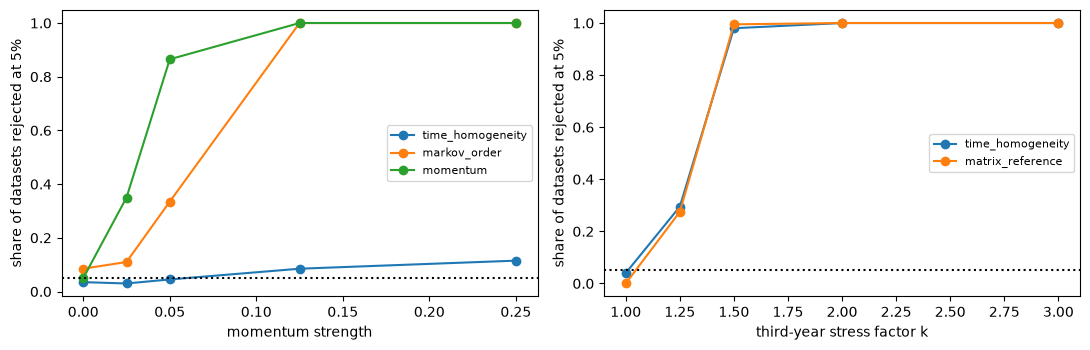

In [13]:
# Draw the power curves of the tests along the two ladders
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for t in ids_m:
    left.plot(strengths, rates_m[t], marker="o", label=t[7:])
for t in ids_c:
    right.plot(factors, rates_c[t], marker="o", label=t[7:])
left.set_xlabel("momentum strength")
right.set_xlabel("third-year stress factor k")
for ax in (left, right):
    ax.axhline(0.05, color="black", linestyle=":")
    ax.set_ylabel("share of datasets rejected at 5%")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The left panel is the answer to which test sees momentum: at strength 0.125 the order and the momentum tests reject 100% of the datasets, and the homogeneity test only 8.5%, against 3.5% when there is none. The right panel is the mirror image: a stressed third year is seen by homogeneity (29.5% at k = 1.25 and 98% at k = 1.5) and by the year-against-pooled test, which a Markov chain with momentum would not trip. At zero strength the order test rejects 8.5% of the datasets and the momentum test 5%, near the nominal level. The curves are a property of this design, five years and 7,113 obligors, and a smaller portfolio would shift all of them to the right.

### Step 6: the chain against the cohort that lived it

The point of a matrix is a projection. The artifact holds, for five windows of five years, the fixed cohort of the window's first year followed to its end (`outputs.lifetime`) beside what the window's one-year matrices project. Three numbers need to be told apart. **Lived, defaulted (`cumulative_d2`)**: every rated defaulter, from the default page. **Lived, in default at the end (`default_end`)**: ratings still in a default category on the transition page at the window's end, which misses defaults withdrawn or re-rated within the window. **Chained**: the window's five annual matrices multiplied, withdrawals as an absorbing state, so a rating that defaulted counts; by definition it lies between the other two. The pooled matrix to the fifth power and the EM generator project the same horizon without the window's own matrices.

The next cell chains the five annual matrices of the window 2020 to 2024 with the engine, once with the withdrawn ratings as a state and once with them removed, raises the pooled matrix to the fifth power, takes the five-year EM projection, and sets them beside what the cohort lived.

In [14]:
# Chain the five annual matrices, project with the pooled matrix and EM, read what the cohort lived
window = out["lifetime"][-1]
span = [c for c in cohorts if int(window["first"]) <= int(c["label"]) <= int(window["last"])]
chain_state, chain_exclude = np.eye(9), np.eye(8)
for c in span:
    table = np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))])
    gone_c = np.append(np.array(c["withdrawn"], dtype=float), 0.0)
    chain_state = chain_state @ estimators.cohort(table, gone_c, treatment="state")["matrix"]
    chain_exclude = chain_exclude @ estimators.cohort(table, gone_c, treatment="exclude")["matrix"]
em = em_generator([{"counts": t, "dt": 1.0} for t in annual])
rows = (
    ("lived: every defaulter", np.array(window["observed"]["cumulative_d2"])),
    ("lived: in default at the end", np.array(window["observed"]["default_end"])),
    ("chained, withdrawals a state", chain_state[:7, 7]),
    ("chained, withdrawals removed", chain_exclude[:7, 7]),
    ("pooled matrix to the fifth power", np.linalg.matrix_power(P, 5)[:7, 7]),
    ("EM generator, five years", expm(5 * em["generator"])[:7, 7]),
)
withdrawn_end = np.array(window["observed"]["withdrawn_end"])

print("window:", window["label"], "| cohort sizes, B and CCC-C:", window["size"][5], window["size"][6])
print(f"{'':58s}{'B':>10s}{'CCC-C':>10s}")
for label, values in rows:
    print(f"{label:58s}{values[5]:10.4f}{values[6]:10.4f}")
print(f"{'share withdrawn by the end':58s}{withdrawn_end[5]:10.4f}{withdrawn_end[6]:10.4f}")

window: 2020-2024 | cohort sizes, B and CCC-C: 1846 238
                                                                   B     CCC-C
lived: every defaulter                                        0.1126    0.6144
lived: in default at the end                                  0.0060    0.0000
chained, withdrawals a state                                  0.0259    0.0910
chained, withdrawals removed                                  0.0440    0.2047
pooled matrix to the fifth power                              0.0821    0.2530
EM generator, five years                                      0.0821    0.2527
share withdrawn by the end                                    0.5531    0.8109


The next cell draws the six readings for B and CCC-C side by side.

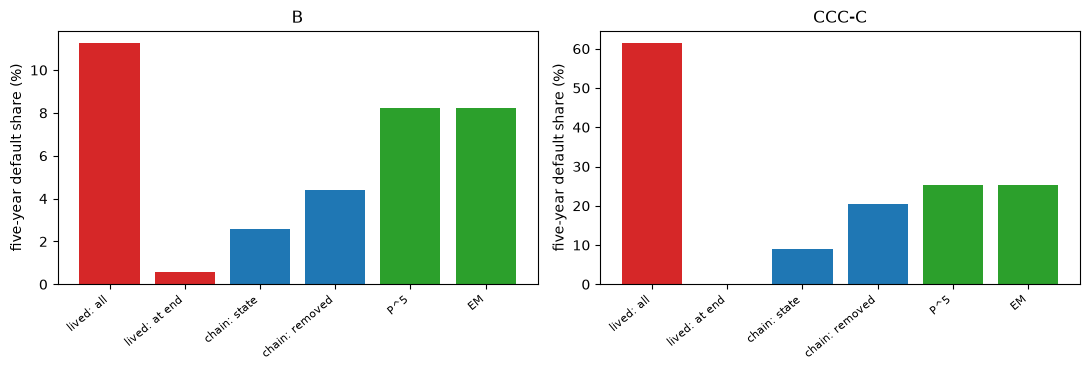

In [15]:
# Draw the five-year default share of B and CCC-C under each reading
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
names = ["lived: all", "lived: at end", "chain: state",
         "chain: removed", "P^5", "EM"]
for ax, g in zip(axes, (5, 6)):
    colors = ["tab:red", "tab:red", "tab:blue", "tab:blue", "tab:green", "tab:green"]
    ax.bar(names, [100 * v[g] for _, v in rows], color=colors)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8)
    ax.set_ylabel("five-year default share (%)")
    ax.set_title(grades[g])
fig.tight_layout()
plt.show()

Three different numbers hide behind "the default frequency of the cohort". Counting every rated defaulter, 61.4% of the CCC-C cohort of 2020 defaulted within the window, yet none of them is still in default at the end, and 81.1% were withdrawn. Chaining the annual matrices with the withdrawals as a state gives 9.1%, between the two lived readings as its definition requires, and removing the withdrawals gives 20.5%. The pooled matrix to the fifth power gives 25.3%, a projection that never saw the window. The figure shows that with four fifths of the cohort gone through withdrawal, the comparison cannot separate a failure of the Markov chain from the way withdrawals are counted.

## Results

**Answer:** no single matrix describes the cohorts, and the test that says so is not the test that finds momentum. The annual homogeneity statistic is 12028.16 on 1075 degrees of freedom, 11.2 times its degrees of freedom, and each of the 26 years rejects the pooled matrix. But on a seeded dataset with planted momentum the order test (p = 2e-13) and the momentum test (fitted c = 0.35) reject while the homogeneity test does not (p = 0.43); over 200 datasets at strength 0.125 homogeneity rejects 8.5% against 100% for the order and momentum tests, while a stressed third year is the case homogeneity sees (29.5% at k = 1.25, 98% at k = 1.5).

- **The ECB's stability tests.** The matrix weighted bandwidth is descriptive and carries no light; the migration z-tests, Holm-adjusted across cells, flag 2 of the 26 cohorts at 5%.
- **Mobility.** The pooled matrix has M_SVD 0.135 and trace index 0.137; the most mobile year is 2002 (0.219) and the least 2023 (0.066), and M_SVD correlates 0.27 with the speculative-grade default rate.
- **Chained against lived.** In the 2020 to 2024 window 61.4% of the CCC-C cohort defaulted (every rated defaulter) while none was still in default at the end and 81.1% had been withdrawn; the chained annual matrices give 9.1% and the pooled matrix to the fifth power 25.3%. For B the readings are 11.3% lived, 2.6% chained and 8.2% pooled power.

What this notebook does not show: how to carry a PD curve to a new year (notebook 05), or what a PD costs in capital (notebook 07).

## Summary

- Time homogeneity, the year-against-pooled test, the order test and the momentum test ask different questions; a rejection of one does not name the departure, and a pass does not clear the chain of the others.
- The ECB's matrix weighted bandwidth is descriptive and its migration z-tests, adjusted across cells, flag few cohorts here; the mobility indices move with the cycle but are not the default rate.
- Rating counts alone support homogeneity and the ECB tests; order and momentum need paths, so they run on simulated paths of known truth.
- A projection is compared with what a cohort lived only after saying which of the three default numbers each counts.

**What to try next.** Change the momentum strength in the draw of Step 5 to 0.05 and rerun it with other seeds; then read notebook 05.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 3.1, 3.5, 3.8 and 3.12. https://doi.org/10.1214/aoms/1177707039
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.5 (matrix weighted bandwidth and migration z-tests). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Jafry, Y. and Schuermann, T. (2004), Measurement, estimation and comparison of credit migration matrices, Journal of Banking and Finance 28(11), for the mobility indices.
- dos Reis, G., Pfeuffer, M. and Smith, G. (2020), Capturing model risk and rating momentum in the estimation of probabilities of default and credit rating migrations, Quantitative Finance, arXiv 1809.09889.
- Holm, S. (1979), A simple sequentially rejective multiple test procedure, Scandinavian Journal of Statistics 6(2), for the adjustment across cells.